# 09 Síntesis de entrega y reporte

Este notebook consolida resultados publicados para el informe, la web y el ensayo de exposición. Es una capa de lectura: no recalcula Spark, clustering, SVD, recomendación ni comunidades.

In [1]:
from __future__ import annotations

import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

ROOT = Path.cwd().resolve()
if not (ROOT / 'artifacts').exists():
    ROOT = ROOT.parent

def require_success(path: Path) -> Path:
    if not (path / '_SUCCESS').is_file():
        raise FileNotFoundError(f'No hay un artefacto publicado completo: {path}')
    return path

def read_json(path: Path) -> dict:
    return json.loads(path.read_text(encoding='utf-8'))

## Resumen congelado

Las cifras se leen de sus metadatos en lugar de copiarse manualmente. Esto evita que el informe presente números de otra corrida.

In [2]:
p1_dir = require_success(ROOT / 'artifacts/p1/analysis')
links_dir = require_success(ROOT / 'artifacts/p2/links')
overlap_dir = require_success(ROOT / 'artifacts/p2/overlap_puno')
profiles_dir = require_success(ROOT / 'artifacts/buyer_clustering')
svd_dir = require_success(ROOT / 'artifacts/p2/svd')
convergence_dir = require_success(ROOT / 'artifacts/p2/convergence')

p1 = pd.read_csv(p1_dir / 'association_results.csv')
p1_primary = p1.loc[
    (p1.scenario == 'all_awards')
    & (p1.participation_measure == 'reported_participants_median')
    & (p1.minimum_processes == 10)
    & (p1.adjustment == 'stratum_centered')
].iloc[0]
links = read_json(links_dir / 'metadata.json')
overlap = read_json(overlap_dir / 'metadata.json')
profiles = read_json(profiles_dir / 'metadata.json')
svd = read_json(svd_dir / 'metadata.json')
convergence = read_json(convergence_dir / 'metadata.json')
summary = pd.DataFrame([
    ['P1', 'Spearman ajustado', p1_primary.correlation],
    ['P1', 'IC bootstrap inferior', p1_primary.ci_low],
    ['P1', 'IC bootstrap superior', p1_primary.ci_high],
    ['P2', 'Nodos de co-participación k<=30', links['pagerank']['nodes']],
    ['P2', 'Aristas de co-participación k<=30', links['pagerank']['undirected_edges']],
    ['Parte V', 'Participantes Puno con membresías múltiples', overlap['coverage']['share_nodes_in_multiple_communities']],
    ['Parte VI', 'Silueta perfiles k=5', profiles['kmeans_selected']['silhouette']],
    ['Parte VI', 'Varianza explicada SVD', svd['explained_variance_ratio_sum']],
    ['Parte VII', 'NMI perfil--comunidad', convergence['nmi_profile_cluster_dominant_community']],
], columns=['parte', 'indicador', 'valor'])
display(summary)

,parte,indicador,valor
0,P1,Spearman ajustado,-5.038790e-02
1,P1,IC bootstrap inferior,-1.362607e-01
2,P1,IC bootstrap superior,7.834653e-02
3,P2,Nodos de co-participación k<=30,2.537900e+04
4,P2,Aristas de co-participación k<=30,1.698528e+06
5,Parte V,Participantes Puno con membresías múltiples,3.370021e-01
6,Parte VI,Silueta perfiles k=5,3.432247e-01
7,Parte VI,Varianza explicada SVD,3.545852e-01
8,Parte VII,NMI perfil--comunidad,1.366767e-01


## Recomendación retrospectiva

La prueba de 2024 compara actores conocidos y relaciones nuevas, no disponibilidad histórica comprobada ni entidades o proveedores fríos. La tabla y figura presentan métricas ya publicadas.

,método,k,recall,precision,ndcg
0,popularidad,10,0.0303,0.0133,0.0252
1,popularidad,20,0.0424,0.0090,0.0282
2,vecindario,10,0.0544,0.0276,0.0554
3,vecindario,20,0.0762,0.0201,0.0606
4,als,10,0.0748,0.0340,0.0657
5,als,20,0.1087,0.0263,0.0754
6,híbrido RRF (validación 2023),10,0.0424,0.0225,0.0400
7,híbrido RRF (validación 2023),20,0.0636,0.0173,0.0461


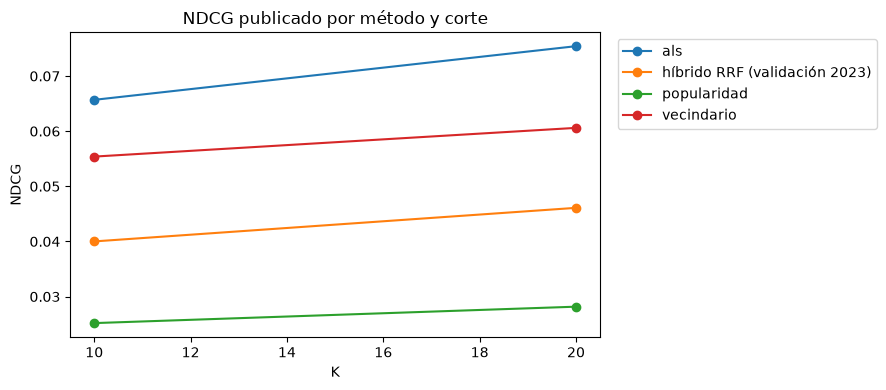

In [3]:
test_dir = require_success(ROOT / 'artifacts/recommendation_test')
hybrid_dir = require_success(ROOT / 'artifacts/recommendation_hybrid')
rec_test = read_json(test_dir / '_metadata.json')
hybrid = read_json(hybrid_dir / '_metadata.json')
rows = []
for method, values in rec_test['metrics_macro'].items():
    for k in (10, 20):
        rows.append({'método': method, 'k': k, **values[str(k)]})
for k in (10, 20):
    rows.append({'método': 'híbrido RRF (validación 2023)', 'k': k, **hybrid['metrics_macro'][str(k)]})
recommendation = pd.DataFrame(rows)
display(recommendation.style.format({'recall': '{:.4f}', 'precision': '{:.4f}', 'ndcg': '{:.4f}'}))

fig, ax = plt.subplots(figsize=(9, 4))
for method, group in recommendation.groupby('método'):
    ax.plot(group.k, group.ndcg, marker='o', label=method)
ax.set(xlabel='K', ylabel='NDCG', title='NDCG publicado por método y corte')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()

## Qué converge y qué no

Los cinco perfiles de compradores, la SVD de ocho componentes y las comunidades representan objetos y criterios distintos. Una NMI baja es un hallazgo descriptivo: no se debe optimizar artificialmente para lograr coincidencia.

,componente,varianza explicada
0,1,9.04%
1,2,8.36%
2,3,5.30%
3,4,5.06%
4,5,3.15%
5,6,1.74%
6,7,1.49%
7,8,1.32%


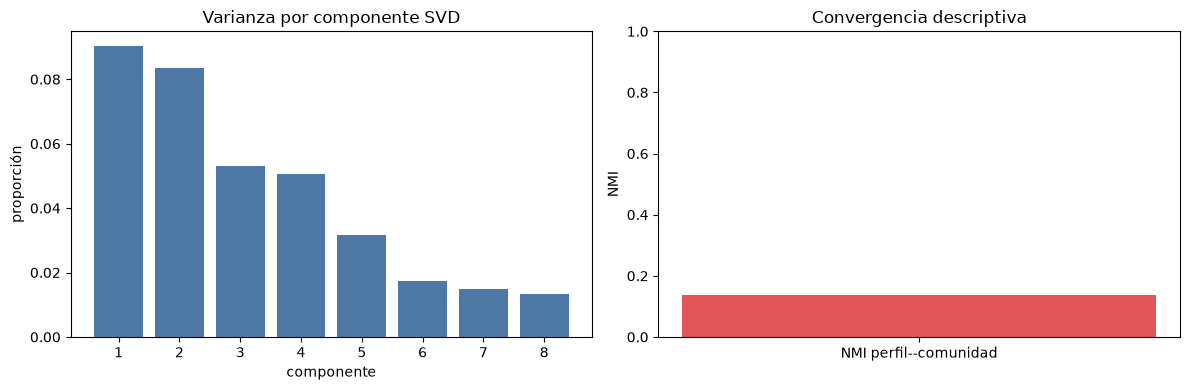

In [4]:
variance = pd.DataFrame({
    'componente': range(1, len(svd['explained_variance_ratio']) + 1),
    'varianza explicada': svd['explained_variance_ratio'],
})
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(variance.componente, variance['varianza explicada'], color='#4e79a7')
axes[0].set(title='Varianza por componente SVD', xlabel='componente', ylabel='proporción')
axes[1].bar(['NMI perfil--comunidad'], [convergence['nmi_profile_cluster_dominant_community']], color='#e15759')
axes[1].set(title='Convergencia descriptiva', ylim=(0, 1), ylabel='NMI')
plt.tight_layout()
display(variance.style.format({'varianza explicada': '{:.2%}'}))

## Mensajes para el informe y la sustentación

1. P1 no sostiene una asociación ajustada persistente entre concentración y participación reportada; no es una conclusión causal.
2. P2 identifica estructura de co-participación reportada. La partición Louvain y el solapamiento BigCLAM en Puno son descripciones de red, no acusaciones.
3. ALS es la referencia retrospectiva para actores conocidos; el híbrido es una sensibilidad que no la supera.
4. Identidad canónica, disponibilidad histórica, arranque en frío y validación externa de `tenderers` permanecen como límites explícitos.

In [5]:
assert round(float(p1_primary.correlation), 3) == -0.050
assert profiles['kmeans_selected']['k'] == 5
assert round(svd['explained_variance_ratio_sum'] * 100, 2) == 35.46
assert round(convergence['nmi_profile_cluster_dominant_community'], 3) == 0.137
assert hybrid['metrics_macro']['10']['ndcg'] < 0.056
print('Síntesis consistente con los artefactos de la entrega.')

Síntesis consistente con los artefactos de la entrega.
